In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import ast 

import warnings
warnings.filterwarnings("ignore")

In [2]:
raw_data = pd.read_csv(r'C:\Users\MAJEED\Desktop\APPS\data_jobs.csv')
raw_data.head()

,job_title_short,job_title,job_location,job_via,job_schedule_type,job_work_from_home,search_location,job_posted_date,job_no_degree_mention,job_health_insurance,job_country,salary_rate,salary_year_avg,salary_hour_avg,company_name,job_skills,job_type_skills
0,Senior Data Engineer,Senior Clinical Data Engineer / Principal Clin...,"Watertown, CT",via Work Nearby,Full-time,False,"Texas, United States",2023-06-16 13:44:15,False,False,United States,NaN,NaN,NaN,Boehringer Ingelheim,NaN,NaN
1,Data Analyst,Data Analyst,"Guadalajara, Jalisco, Mexico",via BeBee México,Full-time,False,Mexico,2023-01-14 13:18:07,False,False,Mexico,NaN,NaN,NaN,Hewlett Packard Enterprise,"['r', 'python', 'sql', 'nosql', 'power bi', 't...","{'analyst_tools': ['power bi', 'tableau'], 'pr..."
2,Data Engineer,"Data Engineer/Scientist/Analyst, Mid or Senior...","Berlin, Germany",via LinkedIn,Full-time,False,Germany,2023-10-10 13:14:55,False,False,Germany,NaN,NaN,NaN,ALPHA Augmented Services,"['python', 'sql', 'c#', 'azure', 'airflow', 'd...","{'analyst_tools': ['dax'], 'cloud': ['azure'],..."
3,Data Engineer,LEAD ENGINEER - PRINCIPAL ANALYST - PRINCIPAL ...,"San Antonio, TX",via Diversity.com,Full-time,False,"Texas, United States",2023-07-04 13:01:41,True,False,United States,NaN,NaN,NaN,Southwest Research Institute,"['python', 'c++', 'java', 'matlab', 'aws', 'te...","{'cloud': ['aws'], 'libraries': ['tensorflow',..."
4,Data Engineer,Data Engineer- Sr Jobs,"Washington, DC",via Clearance Jobs,Full-time,False,Sudan,2023-08-07 14:29:36,False,False,Sudan,NaN,NaN,NaN,Kristina Daniel,"['bash', 'python', 'oracle', 'aws', 'ansible',...","{'cloud': ['oracle', 'aws'], 'other': ['ansibl..."


In [3]:
df = raw_data.copy()

In [4]:
df['job_posted_date'] = pd.to_datetime(df['job_posted_date'])

df['job_posted_month'] = df['job_posted_date'].dt.strftime('%b')

In [5]:
df.dropna(subset = ['job_skills'], inplace = True)

In [6]:
def clean_list(skill_clean):
    return ast.literal_eval(skill_clean)

In [7]:
df['job_skills'] = df['job_skills'].apply(clean_list)

In [8]:
df_DA_US = df[(df['job_title_short'] == 'Data Analyst') & (df['job_country'] == 'United States')]
df_DA_US.head()

,job_title_short,job_title,job_location,job_via,job_schedule_type,job_work_from_home,search_location,job_posted_date,job_no_degree_mention,job_health_insurance,job_country,salary_rate,salary_year_avg,salary_hour_avg,company_name,job_skills,job_type_skills,job_posted_month
68,Data Analyst,Sr. Research Data Analyst,"Baltimore, MD",via ZipRecruiter,Full-time,False,"New York, United States",2023-03-24 13:01:00,False,False,United States,NaN,NaN,NaN,Johns Hopkins Medicine,"[r, zoom]","{'programming': ['r'], 'sync': ['zoom']}",Mar
73,Data Analyst,Entry level / Systems Data Analyst (Remote),Anywhere,via LinkedIn,Contractor,True,"Illinois, United States",2023-06-16 13:18:22,True,True,United States,NaN,NaN,NaN,Soft Magic,"[word, excel, powerpoint, outlook]","{'analyst_tools': ['word', 'excel', 'powerpoin...",Jun
79,Data Analyst,Data Analyst/Report Writer,"Austin, TX",via Jobs Trabajo.org,Full-time,False,"Texas, United States",2023-08-07 13:18:27,True,False,United States,NaN,NaN,NaN,Nesco Resource,"[sas, sas, word, excel]","{'analyst_tools': ['sas', 'word', 'excel'], 'p...",Aug
93,Data Analyst,IT Finance / TBM Data Analyst - Remote | WFH,Anywhere,via LinkedIn,Full-time,True,"New York, United States",2023-06-10 13:00:05,False,False,United States,NaN,NaN,NaN,Get It Recruit - Information Technology,"[oracle, azure, power bi, excel, word, powerpo...","{'analyst_tools': ['power bi', 'excel', 'word'...",Jun
109,Data Analyst,Senior Supply Chain Analytics Analyst,Anywhere,via Get.It,Full-time,True,"Illinois, United States",2023-10-12 13:02:19,False,True,United States,year,89000.0,NaN,Get It Recruit - Transportation,"[python, r, alteryx, tableau]","{'analyst_tools': ['alteryx', 'tableau'], 'pro...",Oct


In [9]:
df_DA_US_explode = df_DA_US.explode('job_skills')

In [10]:
df_DA_US_pivot = df_DA_US_explode.pivot_table(columns = 'job_skills', index =  'job_posted_month', aggfunc = 'size', fill_value = 0)

DA_US_counts = df_DA_US.groupby('job_posted_month').size()
df_DA_US_percent = df_DA_US_pivot.div(DA_US_counts/100, axis = 0)
df_DA_US_percent

job_skills,airflow,airtable,alteryx,angular,ansible,apl,arch,asana,asp.net,asp.net core,...,watson,webex,windows,wire,word,workfront,wrike,xamarin,yarn,zoom
job_posted_month,,,,,,,,,,,,,,,,,,,,,
Apr,0.533944,0.019069,3.966438,0.152555,0.057208,0.133486,0.057208,0.095347,0.114416,0.000000,...,0.038139,0.076278,1.639969,0.171625,13.253242,0.152555,0.019069,0.000000,0.000000,0.228833
Aug,0.782222,0.035556,3.324444,0.088889,0.053333,0.177778,0.000000,0.088889,0.053333,0.000000,...,0.053333,0.106667,1.546667,0.071111,13.368889,0.000000,0.000000,0.000000,0.000000,0.462222
Dec,0.616903,0.061690,3.547193,0.308452,0.154226,0.000000,0.092535,0.215916,0.092535,0.000000,...,0.123381,0.185071,1.449722,0.123381,13.911166,0.092535,0.123381,0.000000,0.000000,0.647748
Feb,0.662126,0.000000,3.840333,0.435112,0.075672,0.018918,0.000000,0.264851,0.170261,0.000000,...,0.113507,0.113507,1.740446,0.056754,13.961407,0.056754,0.000000,0.000000,0.000000,0.359440
Jan,0.518617,0.093085,2.739362,0.279255,0.093085,0.013298,0.000000,0.199468,0.226064,0.000000,...,0.093085,0.119681,1.063830,0.039894,12.872340,0.000000,0.093085,0.000000,0.000000,0.398936
Jul,0.956066,0.045527,3.642158,0.113817,0.068290,0.113817,0.113817,0.136581,0.045527,0.000000,...,0.091054,0.022763,1.343046,0.227635,13.362167,0.000000,0.000000,0.000000,0.022763,0.295925
Jun,0.792683,0.101626,3.821138,0.182927,0.081301,0.162602,0.060976,0.142276,0.142276,0.000000,...,0.101626,0.040650,1.402439,0.162602,14.654472,0.101626,0.000000,0.000000,0.000000,0.406504
Mar,0.730337,0.018727,4.101124,0.093633,0.093633,0.112360,0.018727,0.262172,0.205993,0.000000,...,0.131086,0.112360,1.423221,0.093633,13.782772,0.018727,0.018727,0.018727,0.000000,0.299625
May,0.627178,0.069686,3.344948,0.348432,0.185830,0.209059,0.023229,0.116144,0.301974,0.000000,...,0.023229,0.139373,1.556330,0.023229,12.938444,0.069686,0.000000,0.000000,0.000000,0.209059


In [11]:
df_DA_US_percent['job_posted_month_no'] = pd.to_datetime(df_DA_US_percent.index, format = '%b')
df_DA_US_percent['job_posted_month_no'] = df_DA_US_percent['job_posted_month_no'].dt.month
df_DA_US_percent.sort_values(by = 'job_posted_month_no', inplace = True)
df_DA_US_percent.drop(['job_posted_month_no'], axis = 1, inplace = True)
df_DA_US_percent

job_skills,airflow,airtable,alteryx,angular,ansible,apl,arch,asana,asp.net,asp.net core,...,watson,webex,windows,wire,word,workfront,wrike,xamarin,yarn,zoom
job_posted_month,,,,,,,,,,,,,,,,,,,,,
Jan,0.518617,0.093085,2.739362,0.279255,0.093085,0.013298,0.000000,0.199468,0.226064,0.000000,...,0.093085,0.119681,1.063830,0.039894,12.872340,0.000000,0.093085,0.000000,0.000000,0.398936
Feb,0.662126,0.000000,3.840333,0.435112,0.075672,0.018918,0.000000,0.264851,0.170261,0.000000,...,0.113507,0.113507,1.740446,0.056754,13.961407,0.056754,0.000000,0.000000,0.000000,0.359440
Mar,0.730337,0.018727,4.101124,0.093633,0.093633,0.112360,0.018727,0.262172,0.205993,0.000000,...,0.131086,0.112360,1.423221,0.093633,13.782772,0.018727,0.018727,0.018727,0.000000,0.299625
Apr,0.533944,0.019069,3.966438,0.152555,0.057208,0.133486,0.057208,0.095347,0.114416,0.000000,...,0.038139,0.076278,1.639969,0.171625,13.253242,0.152555,0.019069,0.000000,0.000000,0.228833
May,0.627178,0.069686,3.344948,0.348432,0.185830,0.209059,0.023229,0.116144,0.301974,0.000000,...,0.023229,0.139373,1.556330,0.023229,12.938444,0.069686,0.000000,0.000000,0.000000,0.209059
Jun,0.792683,0.101626,3.821138,0.182927,0.081301,0.162602,0.060976,0.142276,0.142276,0.000000,...,0.101626,0.040650,1.402439,0.162602,14.654472,0.101626,0.000000,0.000000,0.000000,0.406504
Jul,0.956066,0.045527,3.642158,0.113817,0.068290,0.113817,0.113817,0.136581,0.045527,0.000000,...,0.091054,0.022763,1.343046,0.227635,13.362167,0.000000,0.000000,0.000000,0.022763,0.295925
Aug,0.782222,0.035556,3.324444,0.088889,0.053333,0.177778,0.000000,0.088889,0.053333,0.000000,...,0.053333,0.106667,1.546667,0.071111,13.368889,0.000000,0.000000,0.000000,0.000000,0.462222
Sep,0.573664,0.078227,3.780965,0.286832,0.052151,0.078227,0.104302,0.104302,0.078227,0.000000,...,0.000000,0.104302,2.086050,0.104302,12.464146,0.000000,0.000000,0.000000,0.026076,0.312907


In [12]:
top_skill = df_DA_US_percent.sum().sort_values(ascending = False).head(6)
top_skill = top_skill.index.tolist()
df_plot = df_DA_US_percent[top_skill]
df_plot.iloc[-1, 2] = df_plot.iloc[-1, 2] + 0.9  #adjusted tableau y coordinate
df_plot

job_skills,sql,excel,tableau,python,sas,power bi
job_posted_month,,,,,,
Jan,61.183511,47.765957,33.085106,29.973404,24.361702,17.779255
Feb,59.931896,48.940598,31.706394,30.609156,22.928490,21.225880
Mar,60.411985,49.831461,33.782772,31.516854,23.183521,19.737828
Apr,61.403509,48.607933,34.115179,32.017544,24.828375,20.156369
May,59.953542,49.198606,33.263647,31.335656,22.578397,19.976771
Jun,58.170732,48.414634,33.089431,32.703252,20.000000,20.101626
Jul,59.389939,48.213066,34.896426,32.733895,22.672433,20.054632
Aug,60.693333,48.551111,34.684444,36.000000,22.684444,21.475556
Sep,59.843546,46.962190,35.280313,32.046936,22.320730,21.382008


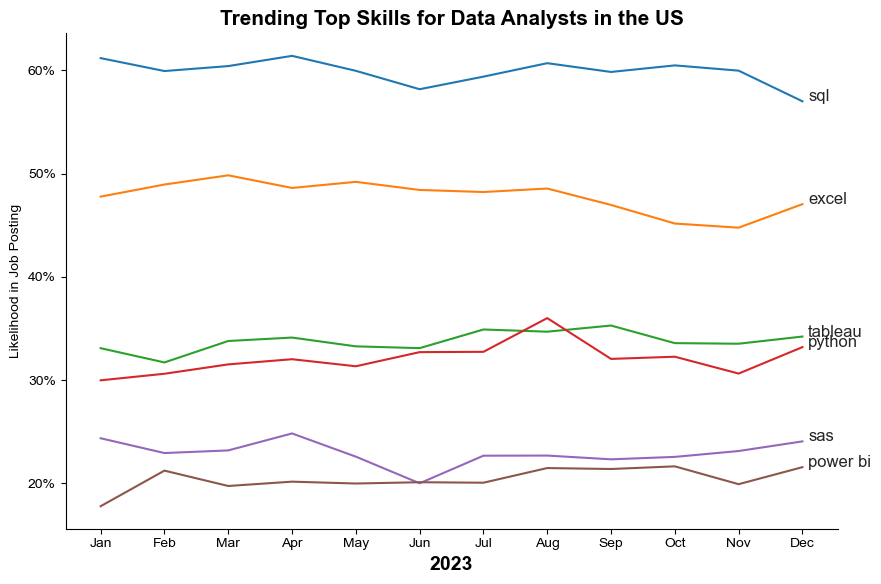

In [13]:
from matplotlib.ticker import PercentFormatter

plt.figure(figsize = (9,6))
sns.lineplot(data = df_plot, dashes = False, palette = 'tab10')
sns.set_theme(style = 'ticks')
sns.despine()

plt.gca().yaxis.set_major_formatter(PercentFormatter(decimals = 0))
plt.ylabel('Likelihood in Job Posting')
plt.xlabel('2023', fontweight = 'bold', fontsize = 14)
plt.title('Trending Top Skills for Data Analysts in the US', fontsize = 15, fontweight = 'bold')
plt.legend().remove()

for i in range(6):
    plt.text(11.09, df_plot.iloc[-1, i], df_plot.columns[i])

plt.tight_layout()
plt.show()